In [2]:
import torch
import torchvision
import numpy as np

In [3]:
print(torch.__version__)
print(torchvision.__version__)

2.14.1
0.29.1


In [4]:
# Creating from a list

data: list[list[int]] = [[1, 2],[3, 4]]
tensor: torch.Tensor = torch.tensor(data)
print(tensor)

tensor([[1, 2],
        [3, 4]])


In [5]:
# Useful attributes of tensors

print(f"Shape of tensor: {tensor.shape}")
print(f"Datatype of tensor: {tensor.dtype}")
print(f"Device tensor is stored on: {tensor.device}")

Shape of tensor: torch.Size([2, 2])
Datatype of tensor: torch.int64
Device tensor is stored on: cpu


In [6]:
# Creating from a numpy array

np_array: np.ndarray = np.array([1, 2, 3])
tensor: torch.Tensor = torch.from_numpy(np_array)
print(tensor)

tensor([1, 2, 3])


In [7]:
# Common helper functions to create tensors

shape: tuple[int, int] = (3, 4)
rand_tensor: torch.Tensor = torch.rand(shape)
ones_tensor: torch.Tensor = torch.ones(shape)
zeros_tensor: torch.Tensor = torch.zeros(shape)

print(f"Random tensor: {rand_tensor}")
print(f"Ones tensor: {ones_tensor}")
print(f"Zeros tensor: {zeros_tensor}")

Random tensor: tensor([[0.3501, 0.3146, 0.2871, 0.9533],
        [0.3589, 0.1794, 0.2942, 0.2893],
        [0.5557, 0.8062, 0.1096, 0.1566]])
Ones tensor: tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]])
Zeros tensor: tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])


In [8]:
# https://pytorch.org/docs/main/tensors.html

tensor: torch.Tensor = torch.tensor([[1, 2, 3], [4, 5, 6]])
print(tensor)
print(tensor.T)
print(tensor.reshape(3, 2))

tensor([[1, 2, 3],
        [4, 5, 6]])
tensor([[1, 4],
        [2, 5],
        [3, 6]])
tensor([[1, 2],
        [3, 4],
        [5, 6]])


In [9]:
# Use numpy-like indexing and slicing on tensors

tensor: torch.Tensor = torch.tensor([[1, 2, 3], [4, 5, 6]])
print(tensor)
print('First row:', tensor[0])
print('First column:', tensor[:, 0])
print('Last column:', tensor[..., -1])

tensor([[1, 2, 3],
        [4, 5, 6]])
First row: tensor([1, 2, 3])
First column: tensor([1, 4])
Last column: tensor([3, 6])


In [10]:
# Some operations on tensors
tensor1: torch.Tensor = torch.tensor([[1, 2], [4, 5]])
tensor2: torch.Tensor = torch.tensor([[7, 8], [10, 11]])

# Element-wise operations
print(tensor1 + tensor2)
print(tensor1 - tensor2)
print(tensor1 * tensor2)
print(tensor1 / tensor2)

# Matrix multiplication
print(tensor1 @ tensor2)
print(tensor1.matmul(tensor2))

tensor([[ 8, 10],
        [14, 16]])
tensor([[-6, -6],
        [-6, -6]])
tensor([[ 7, 16],
        [40, 55]])
tensor([[0.1429, 0.2500],
        [0.4000, 0.4545]])
tensor([[27, 30],
        [78, 87]])
tensor([[27, 30],
        [78, 87]])


In [11]:
# By default, tensors are created on the CPU
# To move to GPU, use .to()

tensor_on_cpu: torch.Tensor = torch.tensor([1, 2, 3])
print(tensor_on_cpu)

if torch.cuda.is_available():
    tensor_on_gpu: torch.Tensor = tensor_on_cpu.to("cuda")
    print(tensor_on_gpu)
else:
    print("CUDA is not available")

tensor([1, 2, 3])
CUDA is not available


In [12]:
# Autograd

# Notice 2.0 as opposed to 2, and 3.0 as opposed to 3, because we want floats
# We set requires_grad=True to track gradients
x: torch.Tensor = torch.tensor(2.0, requires_grad=True)
y: torch.Tensor = torch.tensor(3.0, requires_grad=False)

print(x.dtype)
print(y.dtype)

# Consider the function z = x^2 + 3y
# where x = 2 and y = 3

z = x ** 2 + 3 * y

# Print out the result
print('z =', z)
print('are we tracking gradients?', z.requires_grad)

# Compute the gradient of z with respect to x and y
z.backward()

# dz/dx = 2x
# dz/dy = 3

# This prints 2 * 2 = 4
print('dz/dx =', x.grad)

# This prints None because y.requires_grad = False
# However if we set y.requires_grad = True, then this will print 3
print('dz/dy =', y.grad)

with torch.no_grad():
    w = x ** 2 + 3 * y
    print(w)
    print('are we tracking gradients?', w.requires_grad)

    # This does NOT work because we are not tracking gradients
    # w.backward()

torch.float32
torch.float32
z = tensor(13., grad_fn=<AddBackward0>)
are we tracking gradients? True
dz/dx = tensor(4.)
dz/dy = None
tensor(13.)
are we tracking gradients? False


In [13]:
from torchvision import datasets, transforms

In [14]:
# Dataset stores the samples and their corresponding labels
# https://pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html

import time

def time_operation(operation, *args, **kwargs):
    start_time = time.time()
    result = operation(*args, **kwargs)
    end_time = time.time()
    print(f"Time taken: {end_time - start_time} seconds")
    return result

# Regular calls
# train_dataset = datasets.MNIST('./data', train=True, download=True,
#                                transform=transforms.ToTensor())
# test_dataset = datasets.MNIST('./data', train=False, download=False,
#                               transform=transforms.ToTensor())

# Timed calls
train_dataset: datasets.MNIST = time_operation(datasets.MNIST, './data', train=True, download=True,
                               transform=transforms.ToTensor())
test_dataset: datasets.MNIST = time_operation(datasets.MNIST, './data', train=False, download=True,
                              transform=transforms.ToTensor())

100%|██████████████████████████████████████████████████████████████████████████████| 9.91M/9.91M [00:01<00:00, 8.12MB/s]
100%|███████████████████████████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 326kB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 1.65M/1.65M [00:00<00:00, 3.50MB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 3.13MB/s]

Time taken: 4.4209980964660645 seconds
Time taken: 0.004935741424560547 seconds


In [15]:
print(train_dataset)
print(test_dataset)


Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: ToTensor()
Dataset MNIST
    Number of datapoints: 10000
    Root location: ./data
    Split: Test
    StandardTransform
Transform: ToTensor()


torch.Size([60000, 28, 28])
torch.Size([1, 28, 28])
5


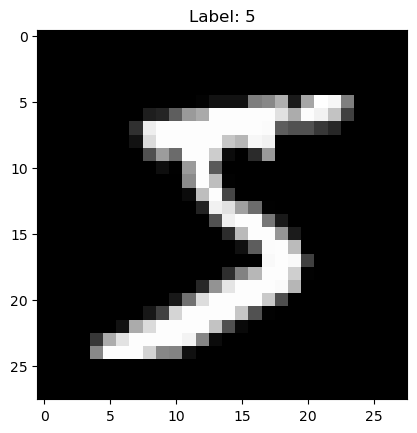

In [16]:
import matplotlib.pyplot as plt
# Dataset stores the samples and their corresponding labels

print(train_dataset.data.shape)

# First sample/element in the training dataset
image: torch.Tensor
label: int

image, label = train_dataset[0]
print(image.shape)
print(label)

# Let's plot the image
plt.imshow(image.squeeze(), cmap='gray')
plt.title(f'Label: {label}')
plt.show()

len of training dataset: 60000
len of training loader: 1875
60000 / 32 = 1875.0
Feature batch shape: torch.Size([32, 1, 28, 28])
Labels batch shape: torch.Size([32])


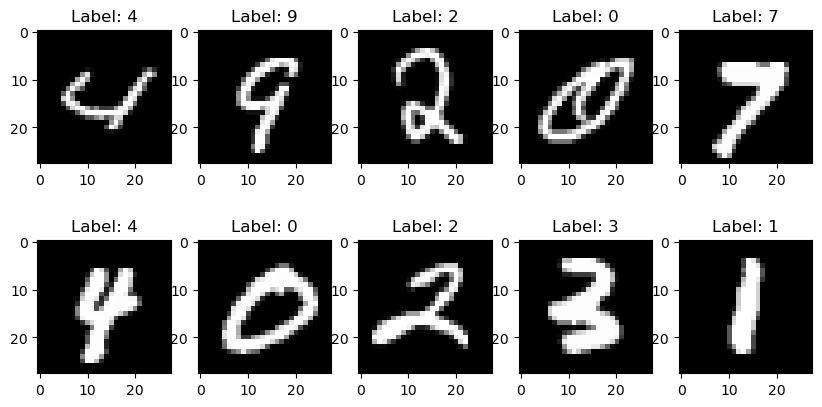

In [17]:
from torch.utils.data import DataLoader

train_loader: DataLoader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader: DataLoader = DataLoader(test_dataset, batch_size=32, shuffle=True)

print('len of training dataset:', len(train_dataset))
print('len of training loader:', len(train_loader))
print('60000 / 32 =', 60000 / 32)

# Let's get the first batch of features and labels
train_features: torch.Tensor
train_labels: torch.Tensor

train_features, train_labels = next(iter(train_loader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")

# Let's plot the first 10 images
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(train_features[i].squeeze(), cmap='gray')
    plt.title(f'Label: {train_labels[i]}')
plt.show()

In [18]:
from torch import nn
# Let's look at some layers

tensor: torch.Tensor = torch.tensor([[1.0, 2, 3], [4, 5, 6]])
print('tensor:', tensor)

# https://pytorch.org/docs/stable/generated/torch.nn.Linear.html
# Notice how the output is a tensor with a grad_fn --> this layer has trainable parameters

linear: nn.Linear = nn.Linear(3, 4)
# Though we fix the starting tensor, this layer has randomly initialized parameters,
# so the output is different each time
print('\nlinear:', linear(tensor))
for name, param in linear.named_parameters():
    print(f'{name}: {param}')

# https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html
relu: nn.ReLU = nn.ReLU()
print('\nrelu:', relu(tensor))
for name, param in relu.named_parameters():
    print(f'{name}: {param}')

# https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html
flatten: nn.Flatten = nn.Flatten()
print('\nflatten:', flatten(tensor))
for name, param in flatten.named_parameters():
    print(f'{name}: {param}')

# https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html
dropout: nn.Dropout = nn.Dropout(0.5)
print('\ndropout:', dropout(tensor))
for name, param in dropout.named_parameters():
    print(f'{name}: {param}')


tensor: tensor([[1., 2., 3.],
        [4., 5., 6.]])

linear: tensor([[ 0.5963, -0.9679,  1.1775,  1.1584],
        [ 2.1941, -0.7095,  3.2345,  2.5041]], grad_fn=<AddmmBackward0>)
weight: Parameter containing:
tensor([[ 0.5214,  0.3603, -0.3491],
        [ 0.3696,  0.0327, -0.3161],
        [ 0.3402, -0.1670,  0.5125],
        [ 0.2869, -0.0522,  0.2139]], requires_grad=True)
bias: Parameter containing:
tensor([ 0.4015, -0.4545, -0.3661,  0.3342], requires_grad=True)

relu: tensor([[1., 2., 3.],
        [4., 5., 6.]])

flatten: tensor([[1., 2., 3.],
        [4., 5., 6.]])

dropout: tensor([[ 0.,  4.,  6.],
        [ 0.,  0., 12.]])


In [19]:
from torch import nn
import torch.nn.functional as F

# nn.Sequential is a container for layers that are executed in order
# https://pytorch.org/docs/stable/generated/torch.nn.Sequential.html
simple_model_1: nn.Sequential = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 20),
    nn.ReLU(),
    nn.Linear(20, 10)
)

# Constructing via subclassing nn.Module (more flexible, but more verbose for simple models)
# https://pytorch.org/docs/stable/generated/torch.nn.Module.html
class SimpleModel(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.flatten = nn.Flatten()
        self.lin1 = nn.Linear(784, 20)
        self.lin2 = nn.Linear(20, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.flatten(x)
        x = self.lin1(x)
        x = F.relu(x)
        x = self.lin2(x)
        return x

simple_model_2: SimpleModel = SimpleModel()

# Let's copy weights from simple_model_1 to simple_model_2
# so that we can see if the two models are equivalent
# (since they are randomly initialized)
simple_model_2.lin1.weight.data = simple_model_1[1].weight.data
simple_model_2.lin1.bias.data = simple_model_1[1].bias.data
simple_model_2.lin2.weight.data = simple_model_1[3].weight.data
simple_model_2.lin2.bias.data = simple_model_1[3].bias.data

# Random sample input -- dimensions don't matter since we flatten
# The first dimension is the batch size
# Batch size refers to the number of samples that will be propagated through the network at once.
# A larger batch size can speed up training but requires more memory, while a smaller batch size
# can provide a more accurate estimate of the gradient but may slow down training.
sample_input = torch.randn(1, 28, 28)

print("Simple Model 1:")
print(simple_model_1)
output_1 = simple_model_1(sample_input)
print("Forward pass output:", output_1)
print("Output dimensions:", output_1.shape)

print("\nSimple Model 2:")
print(simple_model_2)
output_2 = simple_model_2(sample_input)
print("Forward pass output:", output_2)
print("Output dimensions:", output_2.shape)

# Example of a batch size of 2
sample_input_batch = torch.randn(2, 28, 28)

print("\nSimple Model 1 with batch size 2:")
output_1_batch = simple_model_1(sample_input_batch)
print("Forward pass output:", output_1_batch)
print("Output dimensions:", output_1_batch.shape)

print("\nSimple Model 2 with batch size 2:")
output_2_batch = simple_model_2(sample_input_batch)
print("Forward pass output:", output_2_batch)
print("Output dimensions:", output_2_batch.shape)




Simple Model 1:
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=20, bias=True)
  (2): ReLU()
  (3): Linear(in_features=20, out_features=10, bias=True)
)
Forward pass output: tensor([[ 0.0614,  0.2974, -0.1739, -0.3314,  0.1102, -0.3037,  0.2666,  0.1249,
          0.1637,  0.1553]], grad_fn=<AddmmBackward0>)
Output dimensions: torch.Size([1, 10])

Simple Model 2:
SimpleModel(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (lin1): Linear(in_features=784, out_features=20, bias=True)
  (lin2): Linear(in_features=20, out_features=10, bias=True)
)
Forward pass output: tensor([[ 0.0614,  0.2974, -0.1739, -0.3314,  0.1102, -0.3037,  0.2666,  0.1249,
          0.1637,  0.1553]], grad_fn=<AddmmBackward0>)
Output dimensions: torch.Size([1, 10])

Simple Model 1 with batch size 2:
Forward pass output: tensor([[ 0.4749, -0.3078,  0.1197, -0.4844,  0.5575, -0.1703, -0.1030,  0.5006,
          0.0355, -0.0671],
        [ 0.1270, -0.0079, -0.2908, -0.28

In [20]:
# https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html
ce_loss = nn.CrossEntropyLoss()

# Predicted and target values
pred: torch.Tensor = torch.randn(3, 5)
target: torch.Tensor = torch.randn(3, 5)

print('Predicted:', pred)
print('Target:', target)

loss: torch.Tensor = ce_loss(pred, target)
print('Cross Entropy Loss:', loss)

# https://pytorch.org/docs/stable/generated/torch.nn.MSELoss.html
mse_loss = nn.MSELoss()
loss: torch.Tensor = mse_loss(pred, target)
print('MSE Loss:', loss)


Predicted: tensor([[ 0.9699, -1.3183, -0.0790, -0.9554, -1.1344],
        [ 1.1689, -0.3375,  1.6516, -0.5519,  0.2765],
        [-0.1959, -1.1170, -0.3948, -0.1786,  0.7347]])
Target: tensor([[-0.5431,  0.5127,  0.5763,  0.3023, -0.6819],
        [ 0.8712,  0.4105, -0.6069,  0.8478,  0.4337],
        [ 1.4953, -0.1853,  0.7079, -0.4000,  0.0055]])
Cross Entropy Loss: tensor(3.0007)
MSE Loss: tensor(1.4077)


In [21]:
# Example of loss.backward

model: nn.Linear = nn.Linear(2, 1)

# Let's check out its parameters
name: str
param: nn.Parameter
for name, param in model.named_parameters():
    print(f'Data for {name}: {param.data}')
    print(f'Gradient for {name}: {param.grad}\n')
print('Total number of parameters:', sum(p.numel() for p in model.parameters()))

# Generate some random input data and target
input_data: torch.Tensor = torch.randn(1, 2)
target: torch.Tensor = torch.tensor([1.0])

# Let's use mse loss
mse_loss: nn.MSELoss = nn.MSELoss()

# Forward pass: compute predicted outputs by passing inputs to the model
output: torch.Tensor = model(input_data)

print('\nOutput:', output)

# Compute the loss
# Ensure the target tensor has the same dimensions as the output tensor
target = target.view_as(output)
loss: torch.Tensor = mse_loss(output, target)

# Print the loss
print('Loss:', loss.item())
print('')

# Zero the gradients before running the backward pass
model.zero_grad()

# Backward pass: compute gradient of the loss with respect to model parameters
loss.backward()

# Print out the gradients
for name, param in model.named_parameters():
    print(f'Gradient for {name}: {param.grad}')


Data for weight: tensor([[ 0.2443, -0.1362]])
Gradient for weight: None

Data for bias: tensor([0.6111])
Gradient for bias: None

Total number of parameters: 3

Output: tensor([[0.2567]], grad_fn=<AddmmBackward0>)
Loss: 0.552425742149353

Gradient for weight: tensor([[ 1.7705, -0.6918]])
Gradient for bias: tensor([-1.4865])


In [22]:
# What's the need for zero_grad?

# Let's suppose we redo the computation above (this time we don't zero the gradients)
# Note: we have NOT modified any model parameters, so the gradients should be the same

output: torch.Tensor = model(input_data)
loss: torch.Tensor = mse_loss(output, target)

# Omit the zero_grad call
# model.zero_grad()

loss.backward()

# Print out the gradients
name: str
param: nn.Parameter
for name, param in model.named_parameters():
    print(f'Gradient for {name}: {param.grad}')

Gradient for weight: tensor([[ 3.5409, -1.3835]])
Gradient for bias: tensor([-2.9730])


In [23]:
# Example of using an optimizer -- let's reuse the model and loss function from before

# Let's check out the model's parameters
print('====== Start ======')
name: str
param: nn.Parameter
for name, param in model.named_parameters():
    print(f'Data for {name}: {param.data}')
    print(f'Gradient for {name}: {param.grad}\n')

# Define an optimizer
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

# Perform a forward pass & compute the loss
output = model(input_data)
loss = mse_loss(output, target)

# Zero the gradients -- notice how we use optimizer.zero_grad() here instead of model.zero_grad()
# optimizer.zero_grad() only clears the gradients of the parameters that the optimizer is tracking
# Here, we are tracking ALL the model's parameters, so optimizer.zero_grad() is equivalent to model.zero_grad()
# However, in some cases it's useful to NOT assign all the model's parameters to the optimizer
# So, optimizer.zero_grad() is preferred
optimizer.zero_grad()

# Perform a backward pass (do AFTER zeroing the gradients)
loss.backward()

print('====== After loss.backward(): ======')
print('The gradients change\n')
for name, param in model.named_parameters():
    print(f'Data for {name}: {param.data}')
    print(f'> Gradient for {name}: {param.grad}\n')

# Update the weights
optimizer.step()

print('====== After optimizer.step() ======')
print('The weights change\n')
for name, param in model.named_parameters():
    print(f'> Data for {name}: {param.data}')
    print(f'Gradient for {name}: {param.grad}\n')

====== Start ======
Data for weight: tensor([[ 0.2443, -0.1362]])
Gradient for weight: tensor([[ 3.5409, -1.3835]])

Data for bias: tensor([0.6111])
Gradient for bias: tensor([-2.9730])

====== After loss.backward(): ======
The gradients change

Data for weight: tensor([[ 0.2443, -0.1362]])
> Gradient for weight: tensor([[ 1.7705, -0.6918]])

Data for bias: tensor([0.6111])
> Gradient for bias: tensor([-1.4865])

====== After optimizer.step() ======
The weights change

> Data for weight: tensor([[ 0.2266, -0.1293]])
Gradient for weight: tensor([[ 1.7705, -0.6918]])

> Data for bias: tensor([0.6260])
Gradient for bias: tensor([-1.4865])



In [24]:
# Example of using torch.no_grad()

print('====== Before torch.no_grad(): ======')
print('The weights and gradients\n')
for name, param in model.named_parameters():
    print(f'Data for {name}: {param.data}')
    print(f'Gradient for {name}: {param.grad}\n')

# Perform a forward pass without tracking gradients
with torch.no_grad():
    optimizer.zero_grad()
    output = model(input_data)
    loss = mse_loss(output, target)
    # This will raise an error because we are not tracking gradients
    # loss.backward()
    # This does nothing because there are no gradients
    optimizer.step()

print('====== After torch.no_grad(): ======')
print('The weights and gradients remain unchanged b/c we could not call loss.backward() or optimizer.step()\n')
for name, param in model.named_parameters():
    print(f'Data for {name}: {param.data}')
    print(f'Gradient for {name}: {param.grad}\n')


====== Before torch.no_grad(): ======
The weights and gradients

Data for weight: tensor([[ 0.2266, -0.1293]])
Gradient for weight: tensor([[ 1.7705, -0.6918]])

Data for bias: tensor([0.6260])
Gradient for bias: tensor([-1.4865])

====== After torch.no_grad(): ======
The weights and gradients remain unchanged b/c we could not call loss.backward() or optimizer.step()

Data for weight: tensor([[ 0.2266, -0.1293]])
Gradient for weight: None

Data for bias: tensor([0.6260])
Gradient for bias: None



In [25]:
import torch
import torch.nn as nn

# Define a simple model with a dropout layer
model: nn.Sequential = nn.Sequential(
    nn.Linear(10, 5),
    nn.Dropout(0.5),
    nn.Linear(5, 2),
)

# Generate some random input data
input_data = torch.randn(1, 10)
print('Input data:', input_data)

# Set the model to training mode and print the output
model.train()
print('Output in training mode:')
print('Take 1:', model(input_data))
print('Take 2:', model(input_data))

# Set the model to evaluation mode and print the output
# Because the dropout layer is disabled, the output is the same across both calls
model.eval()
print('\nOutput in evaluation mode:')
print('Take 1:', model(input_data))
print('Take 2:', model(input_data))


Input data: tensor([[-0.1250,  0.6339, -0.8749,  0.3212, -1.9980, -0.3386, -1.4237,  1.1534,
         -0.3315, -1.4582]])
Output in training mode:
Take 1: tensor([[0.3378, 0.0165]], grad_fn=<AddmmBackward0>)
Take 2: tensor([[-0.0541, -0.2124]], grad_fn=<AddmmBackward0>)

Output in evaluation mode:
Take 1: tensor([[ 0.2467, -0.4535]], grad_fn=<AddmmBackward0>)
Take 2: tensor([[ 0.2467, -0.4535]], grad_fn=<AddmmBackward0>)
